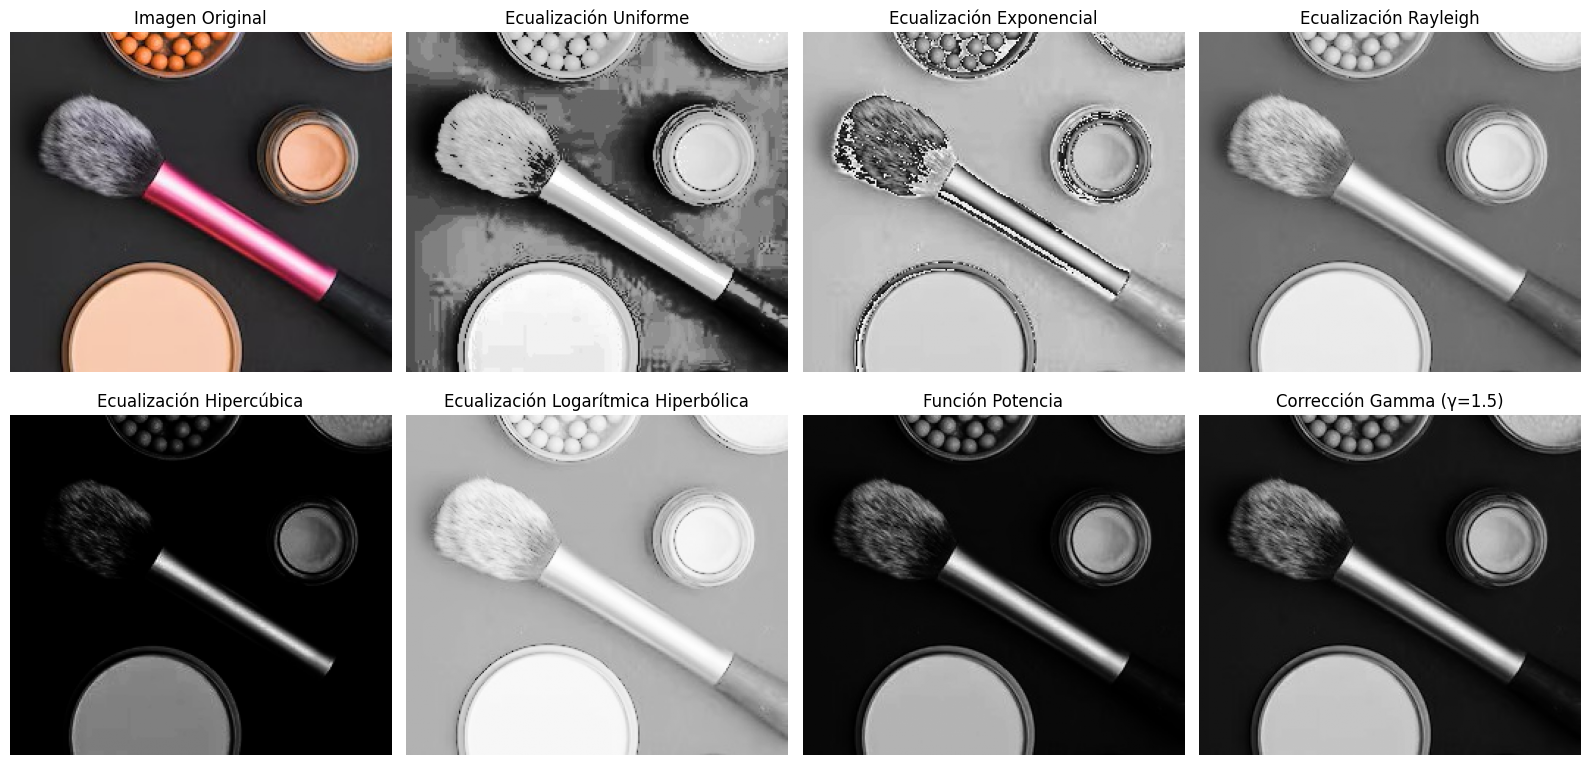

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar imagen en escala de grises
og = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_COLOR_RGB)
imagen = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_GRAYSCALE)

# Ecualización uniforme
uniforme = cv2.equalizeHist(imagen)

# Ecualización exponencial
exp = np.uint8(255 * (1 - np.exp(-imagen / 255)))

# Ecualización Rayleigh
rayleigh = np.uint8(255 * np.sqrt(imagen / 255))

# Ecualización hipercúbica
hipercubica = np.uint8(255 * (imagen / 255) ** 4)

# Ecualización logarítmica hiperbólica
log_hiper = np.uint8(255 * np.log1p(imagen) / np.log1p(255))

# Función potencia
potencia = np.uint8(255 * (imagen / 255) ** 2)

# Corrección Gamma
gamma = 1.5
imagen_gamma = np.power(imagen / 255.0, gamma) * 255
imagen_gamma = np.uint8(imagen_gamma)

imagenes = [
    og,
    uniforme,
    exp,
    rayleigh,
    hipercubica,
    log_hiper,
    potencia,
    imagen_gamma
]

titulos = [
    'Imagen Original',
    'Ecualización Uniforme',
    'Ecualización Exponencial',
    'Ecualización Rayleigh',
    'Ecualización Hipercúbica',
    'Ecualización Logarítmica Hiperbólica',
    'Función Potencia',
    f'Corrección Gamma (γ={gamma})'
]

fig, ejes = plt.subplots(2, 4, figsize=(16, 8))

for eje, img, titulo in zip(ejes.flat, imagenes, titulos):
    eje.imshow(img, cmap='gray')
    eje.set_title(titulo)
    eje.axis('off')

plt.tight_layout()
plt.show()



### Por desplazamiento del histograma

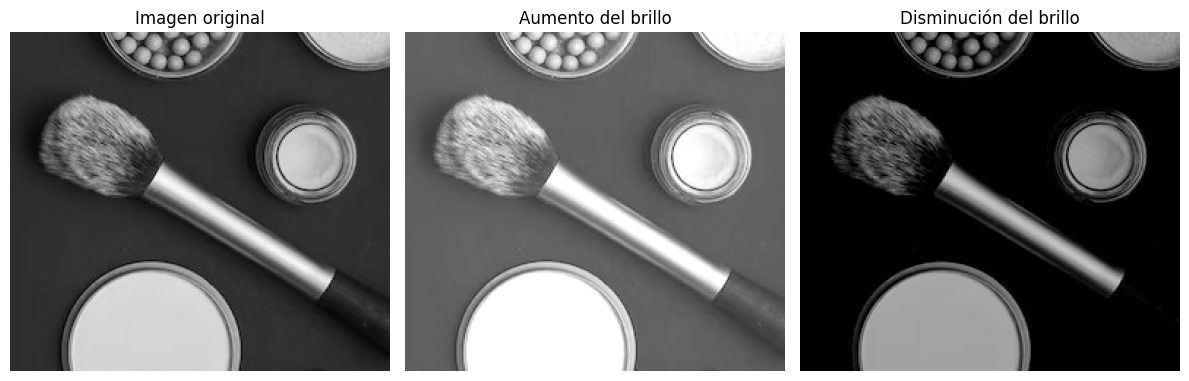

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen en escala de grises
imagen = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_GRAYSCALE)


# Definir el desplazamiento del histograma(positivo o negativo)
desplazamiento = 50  
# Aumentar el brillo
imagen_mas_brillante = cv2.add(imagen, np.full_like(imagen, desplazamiento))

# Disminuir el brillo
imagen_mas_oscura = cv2.subtract(imagen, np.full_like(imagen, desplazamiento))

# Mostrar resultados
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(imagen_mas_brillante, cmap='gray', vmin=0, vmax=255)
plt.title('Aumento del brillo')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(imagen_mas_oscura, cmap='gray', vmin=0, vmax=255)
plt.title('Disminución del brillo')
plt.axis('off')

plt.tight_layout()
plt.show()

### Expansion y contracción del histograma

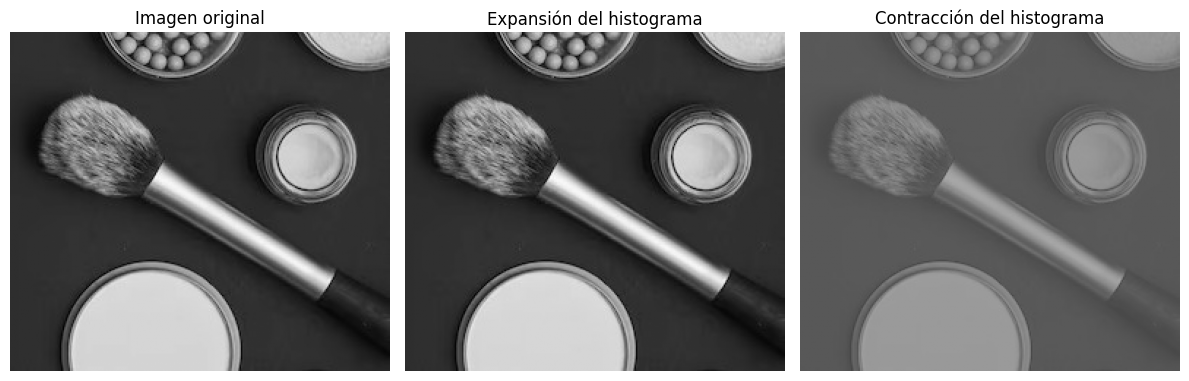

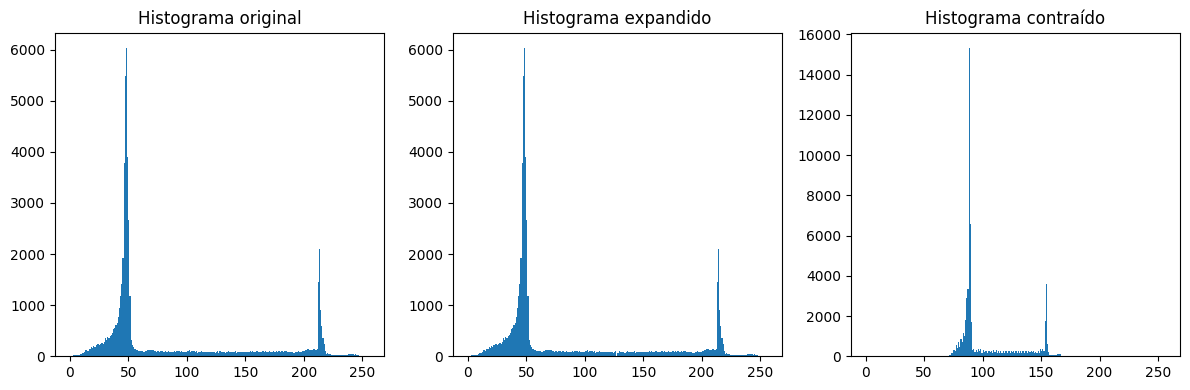

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen en escala de grises
imagen = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_GRAYSCALE)


# Obtener la intensidad mínima y máxima de la imagen
g_min = int(np.min(imagen))
g_max = int(np.max(imagen))

# Evitar división entre cero
if g_max == g_min:
    raise ValueError("La imagen tiene una intensidad constante.")

# EXPANSIÓN DEL HISTOGRAMA
# Llevar las intensidades al rango completo [0, 255]
imagen_expansion = (
    (imagen.astype(np.float32) - g_min)
    * 255 / (g_max - g_min)
)
imagen_expansion = np.clip(imagen_expansion, 0, 255).astype(np.uint8)

# CONTRACCIÓN DEL HISTOGRAMA
# Reducir las intensidades al rango [50, 200]
nuevo_min = 70
nuevo_max = 170

imagen_contraccion = (
    (imagen.astype(np.float32) - g_min)
    * (nuevo_max - nuevo_min) / (g_max - g_min)
    + nuevo_min
)
imagen_contraccion = np.clip(
    imagen_contraccion, 0, 255
).astype(np.uint8)

# Mostrar resultados
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(imagen_expansion, cmap='gray', vmin=0, vmax=255)
plt.title('Expansión del histograma')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(imagen_contraccion, cmap='gray', vmin=0, vmax=255)
plt.title('Contracción del histograma')
plt.axis('off')

plt.tight_layout()
plt.show()

# Mostrar los histogramas
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(imagen.ravel(), bins=256, range=(0, 256))
plt.title('Histograma original')

plt.subplot(1, 3, 2)
plt.hist(imagen_expansion.ravel(), bins=256, range=(0, 256))
plt.title('Histograma expandido')

plt.subplot(1, 3, 3)
plt.hist(imagen_contraccion.ravel(), bins=256, range=(0, 256))
plt.title('Histograma contraído')

plt.tight_layout()
plt.show()